In [1]:
from manim import *
import jupyter_capture_output

video_scene = " -v WARNING --disable_caching gyroscope_Scene"
image_scene = f" -v WARNING --disable_caching -r {2*427},{2*240}  -s gyroscope_Scene"

Jupyter Capture Output v0.0.11


In [251]:
class Gyroscope(Mobject):
	def __init__(self, gyr_origin = np.array([0, 0, 0]), height_total = 6, height_torus = 4, torus_radii = [2, 0.5], **kwargs):
		super().__init__(**kwargs)

		self.gyr_origin = gyr_origin
		self.gyr_height = height_total
		self.torus_height = height_torus
		self.torus_radii = torus_radii
		self.torus_center = self.gyr_origin+np.array([0, 0, self.torus_height])


		CO3D = [1, 1, -16]
		ax = ThreeDAxes(
			x_range = (-4, 4, 1), y_range = (-4, 4, 1), z_range = (0, 7, 1),
			x_length = 12, y_length = 12, z_length = 10, axis_config = {'tip_length': 0.05, 'tip_width': 0.3}, 
			z_axis_config = {'color': WHITE},
			).move_to(CO3D).rotate(
				axis = [1, 0, 0], angle = 6*PI/4, about_point = CO3D
				).rotate(
					axis = [0, 1, 0], angle = 5*PI/4, about_point = CO3D
					).rotate(axis = [1, 0, 0], angle = PI/12).rotate(
						axis = [1, 0, 0], angle = PI/40, about_point = CO3D
						)

		x_lab = Tex('$x$', font_size = 64).move_to(CO3D).shift(5.7*DOWN + 4.7*LEFT)
		y_lab = Tex('$y$', font_size = 64).move_to(CO3D).shift(5.7*DOWN + 4.7*RIGHT)
		z_lab = Tex('$z$', font_size = 64).move_to(CO3D + 0.65*RIGHT).shift(5*UP)
		ax_3D = VGroup(ax, x_lab, y_lab, z_lab)
		self.cs = ax
		self.add(ax_3D)


	def get_gyroscope(self, angles = [0, 0, 0]):
		# creating the gyroscope from mobjects
		center_line = Line3D(start = self.cs.c2p(*self.gyr_origin+np.array([0, 0, 0.75])), end = self.cs.c2p(*(self.gyr_origin+np.array([0, 0, self.gyr_height]))), color = RED, thickness = 0.1)
		cross_line_x = Line3D(start = self.cs.c2p(*self.torus_center+np.array([self.torus_radii[0]*0.7, 0, 0])), end = self.cs.c2p(*self.torus_center+np.array([-self.torus_radii[0]*0.7, 0, 0])), color = RED, thickness = 0.1)
		cross_line_y = Line3D(start = self.cs.c2p(*self.torus_center+np.array([0, self.torus_radii[0]*0.7, 0])), end = self.cs.c2p(*self.torus_center+np.array([0, -self.torus_radii[0]*0.7, 0])), color = RED, thickness = 0.1)

		torus = Torus(
			major_radius = self.torus_radii[0], minor_radius = self.torus_radii[1],
			color = RED, fill_color = RED, resolution = (32, 32), checkerboard_colors = [RED, PURE_RED]
			).move_to(self.cs.c2p(*self.torus_center)).rotate(
				axis = [1, 0, 0], angle = 6*PI/4,
				).rotate(
					axis = [0, 1, 0], angle = 5*PI/4,
					).rotate(axis = [1, 0, 0], angle = PI/12).rotate(
						axis = [1, 0, 0], angle = PI/40,
						)

		cone = Cone(
			base_radius = 0.4, height = 1, direction = (self.cs.c2p(*self.gyr_origin) - self.cs.c2p(*(self.gyr_origin+np.array([0, 0, self.gyr_height])))),
			color = RED, fill_color = RED, checkerboard_colors = [RED, PURE_RED], show_base = True
			).move_to(self.cs.c2p(*self.gyr_origin+np.array([0, 0, 0.375])))

		self.gyr_group = VGroup(center_line, cross_line_x, cross_line_y, torus, cone)

		# rotating the gyroscope according to the given angles
		theta_1 = angles[0]					# rotation along figure axis
		theta_2 = -angles[1]					# tilting the figure axis
		theta_3 = angles[2]					# precession

		rot_z_axis = (self.cs.c2p(0, 0, 1) - self.cs.c2p(*self.gyr_origin))
		rot_x_axis = (self.cs.c2p(1, 0, 0) - self.cs.c2p(-1, 0, 0))

		self.gyr_group.rotate(
			axis = rot_z_axis, angle = theta_1, about_point = self.cs.c2p(*self.gyr_origin)
		).rotate(
			axis = rot_x_axis, angle = theta_2, about_point = self.cs.c2p(*self.gyr_origin)
		).rotate(
			axis = rot_z_axis, angle = theta_3, about_point = self.cs.c2p(*self.gyr_origin)
		)
		# debug_z_line = Line3D(start = self.cs.c2p(1, 0, 0), end = self.cs.c2p(-1, 0, 0), color = BLUE)
		# self.add(debug_z_line)
		return self.gyr_group


Manim Community v0.18.1

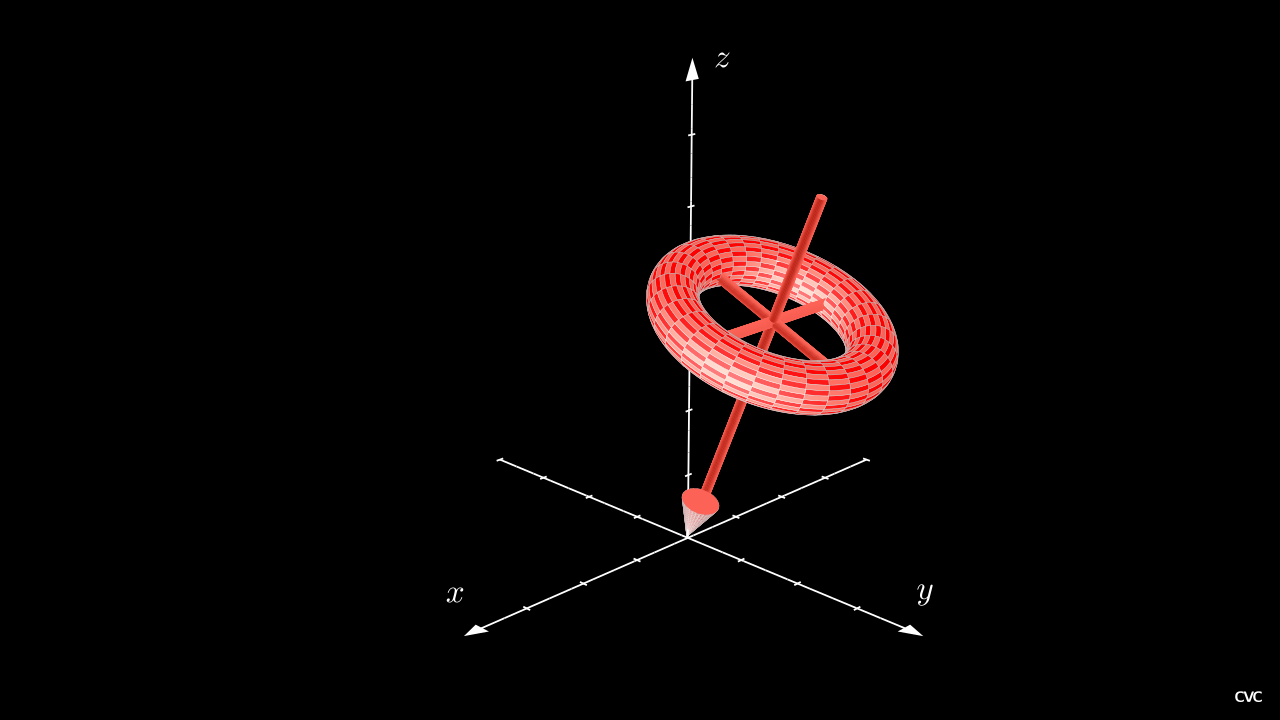

In [252]:
%%manim -qm --fps 60 $video_scene


class gyroscope_Scene(ThreeDScene):
	def construct(self):
		CVC = Text('CVC', font_size = 12, weight = BOLD, color = WHITE, font = 'Latin Modern Sans').align_on_border(RIGHT + DOWN, buff = 0.2)
		self.add(CVC)


		# CO3D = [1, 1, -16]
		# ax = ThreeDAxes(
		# 	x_range = (-4, 4, 1), y_range = (-4, 4, 1), z_range = (0, 7, 1),
		# 	x_length = 12, y_length = 12, z_length = 10, axis_config = {'tip_length': 0.05, 'tip_width': 0.3}, 
		# 	z_axis_config = {'color': WHITE},
		# 	).move_to(CO3D).rotate(
		# 		axis = [1, 0, 0], angle = 6*PI/4
		# 		).rotate(
		# 			axis = [0, 1, 0], angle = 5*PI/4
		# 			).rotate(axis = [1, 0, 0], angle = PI/12).rotate(
		# 				axis = [1, 0, 0], angle = PI/40
		# 				)

		# x_lab = Tex('$x$', font_size = 64).move_to(CO3D).shift(5.7*DOWN + 4.7*LEFT)
		# y_lab = Tex('$y$', font_size = 64).move_to(CO3D).shift(5.7*DOWN + 4.7*RIGHT)
		# z_lab = Tex('$z$', font_size = 64).move_to(CO3D + 0.65*RIGHT).shift(5*UP)
		# ax_3D = VGroup(ax, x_lab, y_lab, z_lab)


		gyroscope = Gyroscope()
		gyroscope_gyroscope = gyroscope.get_gyroscope(np.array([0, PI/8, 0]))
		self.add(gyroscope, gyroscope_gyroscope)